# 7th Mini Project: NLP Text Preprocessing and Representation

## 1. Project Introduction

**Objectives.** Load and verify the complete UCI Sentiment Labelled Sentences dataset; preprocess its reviews; construct word-level one-hot encoding and document-level unigram Bag of Words (BoW), bigrams, and TF-IDF; and interpret vocabulary differences across three domains. No classifier, prediction task, or neural network is introduced.

Text representation converts language into numerical features. The representations studied here differ in their unit of analysis, frequency information, local order, and importance weighting. These differences affect what can be inferred from the features, even before a downstream model is considered.

**Dataset.** The official dataset describes 3,000 labelled sentences: 1,000 each from Amazon product reviews, Yelp restaurant reviews, and IMDb movie reviews, with 500 positive and 500 negative sentences per domain. These are expected properties, not assumed results: Section 2 verifies them from the downloaded files. Domain diversity is valuable because words describing products, food, and films may occupy different parts of a shared vocabulary.

**Official source and attribution:** [UCI Sentiment Labelled Sentences, contributed by Dimitrios Kotzias (2015)](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences). Data are downloaded directly from UCI's public archive. All original rows, including duplicates, are retained.

**Reproducibility.** Run all cells in order in a fresh Python 3 kernel. Internet access is required for the dataset and, initially, NLTK stopwords. The import cell installs only missing required packages into the active kernel environment and reports their versions. Numerical and sampling seeds are fixed. Exact versions and the archive SHA-256 are recorded in the outputs; dependency updates may affect formatting. The notebook creates no local dataset or supplementary submission files.

## 2. Dataset Loading and Exploration

Each source file contains one sentence and its binary label per newline-delimited record. Parsing the **last tab** explicitly avoids treating quotation marks in IMDb text as CSV quoting, which can incorrectly merge records. Records are separated only at the actual LF delimiter, not with `splitlines()`: two IMDb sentences contain embedded U+0085 characters that `splitlines()` incorrectly interprets as extra record boundaries. The original sentence is preserved, and `Domain` records its source. Download, archive, and parsing failures raise explicit actionable errors rather than substituting a different dataset.

In [1]:
import sys
import subprocess
import importlib.metadata
import io
import re
import random
import hashlib
import zipfile
from urllib.request import Request, urlopen
from urllib.error import URLError

required_packages = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'nltk', 'scikit-learn', 'scipy', 'ipython']
missing_packages = []
for package in required_packages:
    try:
        importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        missing_packages.append(package)
if missing_packages:
    print('Installing missing required packages into the active kernel:', missing_packages)
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing_packages], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', 180)
DOMAINS = ['Amazon', 'Yelp', 'IMDb']
display(pd.DataFrame({'Package': required_packages, 'Version': [importlib.metadata.version(p) for p in required_packages]}))

,Package,Version
0,pandas,3.1.1
1,numpy,2.4.6
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,nltk,3.10.4
5,scikit-learn,1.9.1
6,scipy,1.17.1
7,ipython,9.17.1


In [2]:
DATASET_URL = 'https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip'
SOURCE_FILES = {'Amazon': 'amazon_cells_labelled.txt', 'Yelp': 'yelp_labelled.txt', 'IMDb': 'imdb_labelled.txt'}

def load_uci_reviews():
    request = Request(DATASET_URL, headers={'User-Agent': 'NLP-University-Mini-Project/1.0'})
    try:
        with urlopen(request, timeout=60) as response:
            archive_bytes = response.read()
    except (URLError, TimeoutError, OSError) as exc:
        raise RuntimeError('UCI download failed. Check internet access and the official dataset URL, then rerun this cell.') from exc
    records = []
    try:
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            for domain, filename in SOURCE_FILES.items():
                matches = [name for name in archive.namelist() if name.rsplit('/', 1)[-1] == filename and not name.startswith('__MACOSX/')]
                if len(matches) != 1:
                    raise ValueError(f'Expected exactly one archive member for {filename}; found {matches}.')
                lines = archive.read(matches[0]).decode('utf-8-sig').split('\n')
                if lines[-1] == '':
                    lines.pop()
                for line_number, line in enumerate(lines, start=1):
                    parts = line.rsplit('\t', 1)
                    if len(parts) != 2 or parts[1].strip() not in {'0', '1'}:
                        raise ValueError(f'Malformed record in {filename}, line {line_number}.')
                    text, label = parts
                    records.append({'Original_Text': text, 'Label': int(label), 'Domain': domain})
    except (zipfile.BadZipFile, UnicodeDecodeError, KeyError, ValueError) as exc:
        raise RuntimeError(f'UCI archive could not be parsed: {exc}') from exc
    return pd.DataFrame(records), hashlib.sha256(archive_bytes).hexdigest()

df, archive_sha256 = load_uci_reviews()
print('Downloaded from:', DATASET_URL)
print('Archive SHA-256:', archive_sha256)
print('Dataset shape:', df.shape)
display(df.head(10))
display(df.dtypes.rename('Data type').to_frame())
display(df.isna().sum().rename('Missing values').to_frame())
label_counts = df['Label'].value_counts().reindex([0, 1], fill_value=0)
domain_counts = df['Domain'].value_counts().reindex(DOMAINS, fill_value=0)
domain_labels = pd.crosstab(df['Domain'], df['Label']).reindex(index=DOMAINS, columns=[0, 1], fill_value=0)
duplicate_records = int(df.duplicated(['Original_Text', 'Label', 'Domain']).sum())
duplicate_texts = int(df.duplicated('Original_Text').sum())
blank_texts = int(df['Original_Text'].str.strip().eq('').sum())
display(label_counts.rename(index={0: 'Negative (0)', 1: 'Positive (1)'}).rename('Sentences').to_frame())
display(domain_counts.rename('Sentences').to_frame())
display(domain_labels.rename(columns={0: 'Negative (0)', 1: 'Positive (1)'}))
print('Duplicate complete records (beyond the first):', duplicate_records)
print('Repeated original texts (beyond the first, across all domains):', duplicate_texts)
print('Blank original texts:', blank_texts)
assert df.shape == (3000, 3), f'Unexpected dataset shape: {df.shape}'
assert not df.isna().any().any(), 'Unexpected missing source data.'
assert blank_texts == 0, 'Unexpected blank source sentences.'
assert domain_counts.eq(1000).all(), 'Unexpected domain sample counts.'
assert domain_labels.eq(500).all().all(), 'Unexpected domain/class balance.'

Downloaded from: https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip
Archive SHA-256: afc26626d710899948693e1a61405dce197f57ffa719fa1130d346b4cc095343
Dataset shape: (3000, 3)


,Original_Text,Label,Domain
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,Amazon
4,The mic is great.,1,Amazon
5,I have to jiggle the plug to get it to line up right to get decent volume.,0,Amazon
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",0,Amazon
7,If you are Razr owner...you must have this!,1,Amazon
8,"Needless to say, I wasted my money.",0,Amazon
9,What a waste of money and time!.,0,Amazon


,Data type
Original_Text,str
Label,int64
Domain,str


,Missing values
Original_Text,0
Label,0
Domain,0


,Sentences
Label,
Negative (0),1500
Positive (1),1500


,Sentences
Domain,
Amazon,1000
Yelp,1000
IMDb,1000


Label,Negative (0),Positive (1)
Domain,,
Amazon,500,500
Yelp,500,500
IMDb,500,500


Duplicate complete records (beyond the first): 17
Repeated original texts (beyond the first, across all domains): 17
Blank original texts: 0


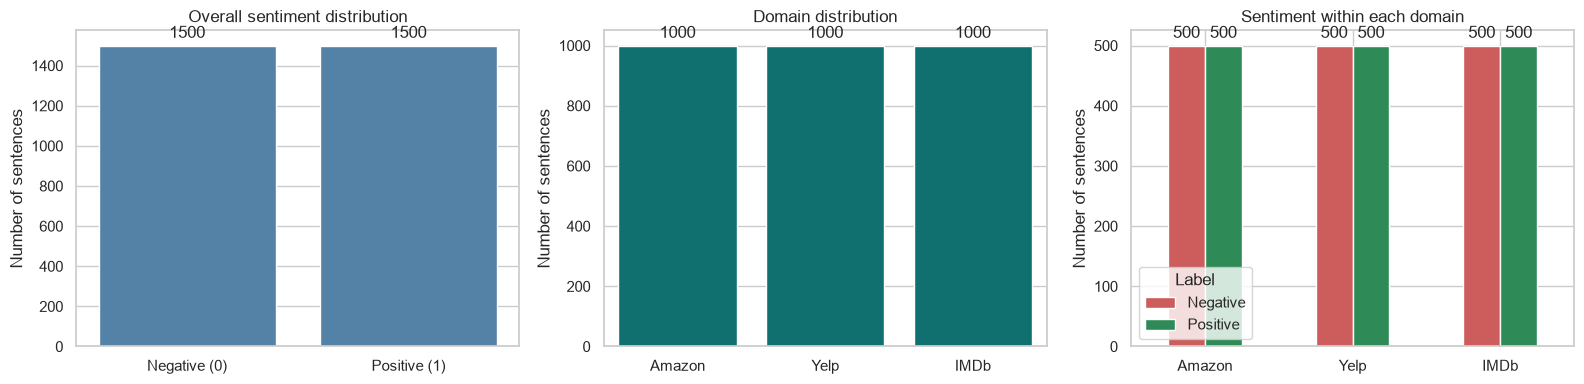

,Original_Text,Label,Domain
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
1001,Crust is not good.,0,Yelp
1000,Wow... Loved this place.,1,Yelp
2000,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",0,IMDb
2004,The best scene in the movie was when Gerardo is trying to find a song that keeps running through...,1,IMDb


**Observed findings.** The downloaded data contain **3,000 sentences** and 3 source columns. Each domain contains 1,000 sentences, and the domain-by-label table confirms 500 examples of each sentiment in each domain. There are 0 missing source values, 0 blank sentences, **17 duplicate complete records**, and 17 repeated texts beyond their first occurrence. Duplicates are retained to analyse the full released dataset; consequently, frequencies and weights include these repetitions. The six displayed records are actual examples of both sentiments from every domain. Balance does not imply that vocabulary, length, or difficulty is identical across domains.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x=['Negative (0)', 'Positive (1)'], y=label_counts.to_numpy(), color='steelblue', ax=axes[0])
sns.barplot(x=DOMAINS, y=domain_counts.to_numpy(), color='teal', ax=axes[1])
domain_labels.rename(columns={0: 'Negative', 1: 'Positive'}).plot.bar(ax=axes[2], rot=0, color=['indianred', 'seagreen'])
for ax, title in zip(axes, ['Overall sentiment distribution', 'Domain distribution', 'Sentiment within each domain']):
    ax.set_title(title)
    ax.set_ylabel('Number of sentences')
    ax.set_xlabel('')
    ax.bar_label(ax.containers[0], padding=3)
axes[2].bar_label(axes[2].containers[1], padding=3)
fig.tight_layout()
plt.show()
examples = pd.concat([df[(df['Domain'] == domain) & (df['Label'] == label)].head(1) for domain in DOMAINS for label in [0, 1]])
display(examples)
display(Markdown(f'**Observed findings.** The downloaded data contain **{len(df):,} sentences** and {df.shape[1]} source columns. Each domain contains {domain_counts.iloc[0]:,} sentences, and the domain-by-label table confirms 500 examples of each sentiment in each domain. There are {int(df.isna().sum().sum())} missing source values, {blank_texts} blank sentences, **{duplicate_records} duplicate complete records**, and {duplicate_texts} repeated texts beyond their first occurrence. Duplicates are retained to analyse the full released dataset; consequently, frequencies and weights include these repetitions. The six displayed records are actual examples of both sentiments from every domain. Balance does not imply that vocabulary, length, or difficulty is identical across domains.'))

## 3. Text Preprocessing

The pipeline applies four operations in order:

1. **Lowercasing:** merge case variants such as a capitalized and lowercase word.
2. **Remove punctuation and special characters:** replace non-letter characters with spaces and collapse whitespace. This deliberately uses an English alphabet policy; numbers and non-ASCII characters are removed as well.
3. **Tokenization:** use NLTK `wordpunct_tokenize` on the cleaned text. No Punkt model is needed because punctuation has already been removed.
4. **Stopword removal:** remove NLTK English stopwords, **except `not`, `no`, and `never`**. These explicit negation tokens must remain available for sentiment and bigram analysis.

`Original_Text` is never modified. `Cleaned_Text`, `Tokenized_Text`, `Final_Tokens`, and `Preprocessed_Text` make intermediate and final states inspectable. Missing or empty inputs return an empty representation safely; invalid non-string, non-missing inputs raise a clear error. We do not stem or lemmatize.

**Important limitation:** this exact punctuation-first pipeline splits contractions: `don't` becomes `don t`. Keeping explicit negation words does not recover contracted negation, punctuation emphasis, or sarcasm. Bigrams are adjacent **after preprocessing**, so removing intervening stopwords can join words that were not adjacent in the original sentence.

,Stage,Vocabulary size,Total tokens
0,Original case-sensitive NLTK tokens (includes punctuation),6006,42242
1,Lowercase cleaned tokens,5091,36132
2,After stopword removal,4953,18448


,Domain,Original_Text,Cleaned_Text,Tokenized_Text,Preprocessed_Text
0,Amazon,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter,"[so, there, is, no, way, for, me, to, plug, it, in, here, in, the, us, unless, i, go, by, a, con...",no way plug us unless go converter
1,Amazon,"Good case, Excellent value.",good case excellent value,"[good, case, excellent, value]",good case excellent value
2,Amazon,Great for the jawbone.,great for the jawbone,"[great, for, the, jawbone]",great jawbone
3,Amazon,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than minutes major problems,"[tied, to, charger, for, conversations, lasting, more, than, minutes, major, problems]",tied charger conversations lasting minutes major problems
1000,Yelp,Wow... Loved this place.,wow loved this place,"[wow, loved, this, place]",wow loved place
1001,Yelp,Crust is not good.,crust is not good,"[crust, is, not, good]",crust not good
1002,Yelp,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty,"[not, tasty, and, the, texture, was, just, nasty]",not tasty texture nasty
1003,Yelp,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stopped by during the late may bank holiday off rick steve recommendation and loved it,"[stopped, by, during, the, late, may, bank, holiday, off, rick, steve, recommendation, and, love...",stopped late may bank holiday rick steve recommendation loved
2000,IMDb,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",a very very very slow moving aimless movie about a distressed drifting young man,"[a, very, very, very, slow, moving, aimless, movie, about, a, distressed, drifting, young, man]",slow moving aimless movie distressed drifting young man
2001,IMDb,"Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.",not sure who was more lost the flat characters or the audience nearly half of whom walked out,"[not, sure, who, was, more, lost, the, flat, characters, or, the, audience, nearly, half, of, wh...",not sure lost flat characters audience nearly half walked


Empty preprocessed documents retained as all-zero feature rows: 3


,Retained token occurrences
never,52
no,83
not,306


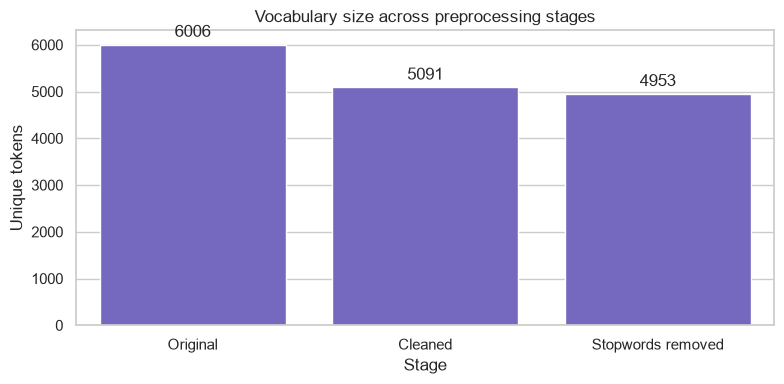

**Observed effect.** The raw tokenizer yields 6,006 distinct case-sensitive tokens including punctuation, versus 5,091 cleaned lowercase word types and **4,953 final vocabulary words**. These stage definitions differ, so the first reduction reflects normalization and character removal, not only stopwords. Stopword removal eliminates 138 word types. The negation table verifies actual retained occurrences. There are 3 empty final documents; they remain in all representations rather than reducing the sample count. The 12 paired examples show what information is removed and retained in every domain. A smaller vocabulary reduces unigram matrix width but can discard useful linguistic distinctions.

In [4]:
try:
    english_stopwords = set(stopwords.words('english'))
except LookupError:
    print('NLTK English stopwords are missing; downloading the official resource.')
    try:
        nltk.download('stopwords', quiet=True, raise_on_error=True)
        english_stopwords = set(stopwords.words('english'))
    except (LookupError, OSError, ValueError) as exc:
        raise RuntimeError('NLTK stopword setup failed. Check internet access and run nltk.download("stopwords") before retrying.') from exc
NEGATIONS = {'not', 'no', 'never'}
stop_words = english_stopwords - NEGATIONS

def preprocess_text(text):
    if text is None or (not isinstance(text, str) and pd.isna(text)):
        return '', [], [], ''
    if not isinstance(text, str):
        raise TypeError('Text must be a string or a missing scalar value.')
    lowered = text.lower()
    cleaned = re.sub(r'[^a-z\s]', ' ', lowered)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    tokens = wordpunct_tokenize(cleaned)
    final_tokens = [token for token in tokens if token not in stop_words]
    return cleaned, tokens, final_tokens, ' '.join(final_tokens)

original_snapshot = df['Original_Text'].copy(deep=True)
processed = df['Original_Text'].map(preprocess_text)
df[['Cleaned_Text', 'Tokenized_Text', 'Final_Tokens', 'Preprocessed_Text']] = pd.DataFrame(processed.tolist(), index=df.index)
assert df['Original_Text'].equals(original_snapshot)
for missing in [None, np.nan, pd.NA, '', '   ', '!!!']:
    assert preprocess_text(missing) == ('', [], [], '')
assert preprocess_text('NOT no never!')[2] == ['not', 'no', 'never']
assert NEGATIONS.isdisjoint(stop_words)
assert len(df) == 3000

documents = df['Preprocessed_Text'].tolist()
raw_tokens = df['Original_Text'].map(wordpunct_tokenize)
raw_vocab = {token for tokens in raw_tokens for token in tokens}
clean_vocab = {token for tokens in df['Tokenized_Text'] for token in tokens}
vocabulary = sorted({token for tokens in df['Final_Tokens'] for token in tokens})
vocab_to_index = {word: index for index, word in enumerate(vocabulary)}
empty_documents = int(df['Preprocessed_Text'].eq('').sum())
vocabulary_summary = pd.DataFrame({'Stage': ['Original case-sensitive NLTK tokens (includes punctuation)', 'Lowercase cleaned tokens', 'After stopword removal'], 'Vocabulary size': [len(raw_vocab), len(clean_vocab), len(vocabulary)], 'Total tokens': [sum(map(len, raw_tokens)), df['Tokenized_Text'].map(len).sum(), df['Final_Tokens'].map(len).sum()]})
display(vocabulary_summary)
display(pd.concat([df[df['Domain'] == domain].head(4) for domain in DOMAINS])[['Domain', 'Original_Text', 'Cleaned_Text', 'Tokenized_Text', 'Preprocessed_Text']])
print('Empty preprocessed documents retained as all-zero feature rows:', empty_documents)
negation_counts = {word: sum(tokens.count(word) for tokens in df['Final_Tokens']) for word in sorted(NEGATIONS)}
display(pd.Series(negation_counts, name='Retained token occurrences').to_frame())
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=['Original', 'Cleaned', 'Stopwords removed'], y=vocabulary_summary['Vocabulary size'], color='slateblue', ax=ax)
ax.set(title='Vocabulary size across preprocessing stages', ylabel='Unique tokens', xlabel='Stage')
ax.bar_label(ax.containers[0], padding=3)
fig.tight_layout()
plt.show()
display(Markdown(f'**Observed effect.** The raw tokenizer yields {len(raw_vocab):,} distinct case-sensitive tokens including punctuation, versus {len(clean_vocab):,} cleaned lowercase word types and **{len(vocabulary):,} final vocabulary words**. These stage definitions differ, so the first reduction reflects normalization and character removal, not only stopwords. Stopword removal eliminates {len(clean_vocab) - len(vocabulary):,} word types. The negation table verifies actual retained occurrences. There are {empty_documents} empty final documents; they remain in all representations rather than reducing the sample count. The 12 paired examples show what information is removed and retained in every domain. A smaller vocabulary reduces unigram matrix width but can discard useful linguistic distinctions.'))

## 4. One-Hot Encoding

Construct one vocabulary from **all** preprocessed documents, sorted alphabetically for deterministic indices. The mapping is `vocab_to_index`; its ordered inverse is `vocabulary`. For a vocabulary of size V, each word is represented by a vector of length V: 1 at its own index and 0 at every other position. Thus a word has exactly one active coordinate, with no frequency, similarity, or word-order information.

To avoid a V-by-V identity matrix, generate only ten sparse word vectors of full width V. The displayed table selects their ten active vocabulary columns; all omitted columns are zero. This is **word-level** encoding, not a document multi-hot representation. The complete mapping is explicitly defined in code, with its first ten entries displayed below.

In [5]:
assert len(vocabulary) >= 10
onehot_words = vocabulary[:10]
onehot_indices = np.array([vocab_to_index[word] for word in onehot_words])
onehot_sample = csr_matrix((np.ones(10, dtype=np.int8), (np.arange(10), onehot_indices)), shape=(10, len(vocabulary)))
display(pd.DataFrame({'Word': onehot_words, 'Vocabulary index': onehot_indices}))
display(pd.DataFrame(onehot_sample[:, onehot_indices].toarray(), index=onehot_words, columns=[f'{word} [{vocab_to_index[word]}]' for word in onehot_words]))
assert np.all(np.asarray(onehot_sample.sum(axis=1)).ravel() == 1)
assert onehot_sample.nnz == 10
print('Full sparse sample shape:', onehot_sample.shape)
display(Markdown(f'**Interpretation.** Each displayed row has one 1 and nine 0s in the selected columns; its remaining {len(vocabulary) - 10:,} coordinates are also zero. The ten generated vectors have full dimensionality **{len(vocabulary):,}**, but only ten stored nonzero values in total. Alphabetically adjacent words do not necessarily have similar meanings: the indices identify tokens, not semantic relationships.'))

,Word,Vocabulary index
0,aailiyah,0
1,abandoned,1
2,abhor,2
3,ability,3
4,able,4
5,abound,5
6,abroad,6
7,absolute,7
8,absolutel,8
9,absolutely,9


,aailiyah [0],abandoned [1],abhor [2],ability [3],able [4],abound [5],abroad [6],absolute [7],absolutel [8],absolutely [9]
aailiyah,1,0,0,0,0,0,0,0,0,0
abandoned,0,1,0,0,0,0,0,0,0,0
abhor,0,0,1,0,0,0,0,0,0,0
ability,0,0,0,1,0,0,0,0,0,0
able,0,0,0,0,1,0,0,0,0,0
abound,0,0,0,0,0,1,0,0,0,0
abroad,0,0,0,0,0,0,1,0,0,0
absolute,0,0,0,0,0,0,0,1,0,0
absolutel,0,0,0,0,0,0,0,0,1,0
absolutely,0,0,0,0,0,0,0,0,0,1


Full sparse sample shape: (10, 4953)


**Interpretation.** Each displayed row has one 1 and nine 0s in the selected columns; its remaining 4,943 coordinates are also zero. The ten generated vectors have full dimensionality **4,953**, but only ten stored nonzero values in total. Alphabetically adjacent words do not necessarily have similar meanings: the indices identify tokens, not semantic relationships.

## 5. Bag of Words (BoW)

`CountVectorizer` counts token occurrences in each document and ignores word order. All vectorizers use the same final text and `str.split` so that even single-letter tokens are retained consistently with the explicit vocabulary. Stopword filtering is not applied again.

For readable matrices, select two token-rich reviews per domain (six documents total). These are deterministic illustrative examples, **not a representative random sample**. Choose the 15 most frequent features within these six documents; display their actual texts, feature names, and counts. Full document-term matrices remain sparse.

In [6]:
vectorizer_options = {'tokenizer': str.split, 'token_pattern': None, 'lowercase': False}
bow_vectorizer = CountVectorizer(**vectorizer_options)
bow_matrix = bow_vectorizer.fit_transform(documents)
unigram_features = bow_vectorizer.get_feature_names_out()
assert unigram_features.tolist() == vocabulary
sample_ids = []
for domain in DOMAINS:
    candidates = df[df['Domain'] == domain].copy()
    candidates['Token_Count'] = candidates['Final_Tokens'].map(len)
    sample_ids.extend(candidates.sort_values('Token_Count', ascending=False, kind='stable').head(2).index.tolist())
doc_names = [f'{df.at[i, "Domain"]} document {i}' for i in sample_ids]

def top_positions(values, count):
    values = np.asarray(values).ravel()
    positive = np.flatnonzero(values > 0)
    return positive[np.argsort(-values[positive], kind='stable')[:count]]

def matrix_sample(matrix, features, row_ids, names, feature_count=15):
    positions = top_positions(matrix[row_ids].sum(axis=0), feature_count)
    return pd.DataFrame(matrix[row_ids][:, positions].toarray(), index=names, columns=features[positions])

selected_unigram_positions = top_positions(bow_matrix[sample_ids].sum(axis=0), 15)
assert len(selected_unigram_positions) == 15
bow_sample = pd.DataFrame(bow_matrix[sample_ids][:, selected_unigram_positions].toarray(), index=doc_names, columns=unigram_features[selected_unigram_positions])
print('BoW document-term matrix shape:', bow_matrix.shape)
print('Selected feature names:', bow_sample.columns.tolist())
display(df.loc[sample_ids, ['Domain', 'Label', 'Original_Text', 'Preprocessed_Text']])
display(bow_sample)
assert np.array_equal(np.asarray(bow_matrix.sum(axis=1)).ravel(), df['Final_Tokens'].map(len).to_numpy())
max_row, max_column = np.unravel_index(np.argmax(bow_sample.to_numpy()), bow_sample.shape)
example_doc = sample_ids[max_row]
example_word = bow_sample.columns[max_column]
example_count = int(bow_sample.iloc[max_row, max_column])
display(Markdown(f'**Observed counts.** The BoW matrix has {bow_matrix.shape[0]:,} document rows and {bow_matrix.shape[1]:,} word columns. In **{doc_names[max_row]}**, `{example_word}` occurs **{example_count} times**, which is the value displayed in its cell. A zero means absence, not negative sentiment. Row sums equal final token counts for every document. Repeating a word increases its count; rearranging the same words would leave a unigram BoW row unchanged.'))

BoW document-term matrix shape: (3000, 4953)
Selected feature names: ['said', 'another', 'dishes', 'hot', 'john', 'not', 'sauce', 'self', 'versus', 'yum', 'aerial', 'arrived', 'art', 'audio', 'bare']


,Domain,Label,Original_Text,Preprocessed_Text
637,Amazon,0,"However, BT headsets are currently not good for real time games like first-person shooters since...",however bt headsets currently not good real time games like first person shooters since audio de...
749,Amazon,1,.... Item arrived quickly and works great with my Metro PCS Samsung SCH-r450 slider phone and So...,item arrived quickly works great metro pcs samsung sch r slider phone sony premium sound ear plugs
1862,Yelp,0,"Hot dishes are not hot, cold dishes are close to room temp.I watched staff prepare food with BAR...",hot dishes not hot cold dishes close room temp watched staff prepare food bare hands no gloves e...
1236,Yelp,0,"The descriptions said ""yum yum sauce"" and another said ""eel sauce"", yet another said ""spicy mayo...",descriptions said yum yum sauce another said eel sauce yet another said spicy mayo well none rol...
2620,IMDb,1,"This is a masterful piece of film-making, with many themes simmering and occasionally boiling ov...",masterful piece film making many themes simmering occasionally boiling warts study poet bohemian...
2390,IMDb,1,"Though The Wind and the Lion is told largely through the eyes of the son, every member of the fa...",though wind lion told largely eyes son every member family identify one characters whether sean ...


,said,another,dishes,hot,john,not,sauce,self,versus,yum,aerial,arrived,art,audio,bare
Amazon document 637,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
Amazon document 749,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Yelp document 1862,0,0,2,2,0,1,0,0,0,0,0,0,0,0,1
Yelp document 1236,3,2,0,0,0,0,2,0,0,2,0,0,0,0,0
IMDb document 2620,0,0,0,0,0,0,0,2,2,0,1,0,1,0,0
IMDb document 2390,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0


**Observed counts.** The BoW matrix has 3,000 document rows and 4,953 word columns. In **Yelp document 1236**, `said` occurs **3 times**, which is the value displayed in its cell. A zero means absence, not negative sentiment. Row sums equal final token counts for every document. Repeating a word increases its count; rearranging the same words would leave a unigram BoW row unchanged.

## 6. Bag of N-Grams (Bigrams)

`CountVectorizer(ngram_range=(2, 2))` represents consecutive pairs of final tokens. Unlike unigram BoW, it distinguishes local order and can encode a negation together with its neighboring word. It still loses global sentence structure and cannot recover stopwords deleted by preprocessing.

The following tables report the 20 most frequent **actual** bigrams, a labelled six-document matrix sample, and actual documents containing retained negation bigrams. These are observations from the dataset, not invented phrase examples.

In [7]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), **vectorizer_options)
bigram_matrix = bigram_vectorizer.fit_transform(documents)
bigram_features = bigram_vectorizer.get_feature_names_out()
bigram_totals = np.asarray(bigram_matrix.sum(axis=0)).ravel()
bigram_top = top_positions(bigram_totals, 20)
assert len(bigram_top) == 20
print('Bigram document-term matrix shape:', bigram_matrix.shape)
display(pd.DataFrame({'Actual bigram': bigram_features[bigram_top], 'Corpus occurrences': bigram_totals[bigram_top]}))
bigram_sample = matrix_sample(bigram_matrix, bigram_features, sample_ids, doc_names)
display(bigram_sample)
assert np.array_equal(np.asarray(bigram_matrix.sum(axis=1)).ravel(), np.maximum(df['Final_Tokens'].map(len).to_numpy() - 1, 0))
negation_positions = np.array([i for i, phrase in enumerate(bigram_features) if any(word in NEGATIONS for word in phrase.split())], dtype=int)
assert len(negation_positions) > 0
negation_top = negation_positions[np.argsort(-bigram_totals[negation_positions], kind='stable')[:5]]
negation_examples = []
for position in negation_top:
    row_id = int(bigram_matrix[:, position].nonzero()[0][0])
    negation_examples.append({'Bigram': bigram_features[position], 'Corpus count': int(bigram_totals[position]), 'Document ID': row_id, 'Domain': df.at[row_id, 'Domain'], 'Original_Text': df.at[row_id, 'Original_Text'], 'Preprocessed_Text': df.at[row_id, 'Preprocessed_Text']})
display(pd.DataFrame(negation_examples))
display(Markdown(f'**Observed comparison.** Bigrams produce **{bigram_matrix.shape[1]:,} pair features**, compared with {bow_matrix.shape[1]:,} unigram features. The most frequent pair is `{bigram_features[bigram_top[0]]}`, observed {int(bigram_totals[bigram_top[0]])} times. An actual negation pair is `{negation_examples[0]["Bigram"]}`; its source sentence and cleaned form are shown above. Unigram BoW counts its two words separately and cannot tell whether they appear next to each other or in this order. Bigram row sums equal max(final token count - 1, 0), as checked for all 3,000 documents. The displayed pairs describe adjacency in preprocessed text, not necessarily adjacency in the original review.'))

Bigram document-term matrix shape: (3000, 14026)


,Actual bigram,Corpus occurrences
0,not good,22
1,go back,18
2,waste time,17
3,works great,17
4,would not,16
5,customer service,15
6,sound quality,14
7,could not,13
8,not work,13
9,one best,13


,another said,aerial bombardments,arrived quickly,art experience,audio delay,bare hands,bergen feisty,big stick,bohemian self,boiling warts,bombardments london,borderlines friendship,brigand candace,bt headsets,candace bergen
Amazon document 637,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
Amazon document 749,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
Yelp document 1862,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
Yelp document 1236,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0
IMDb document 2620,0,1,0,1,0,0,0,0,1,1,1,1,0,0,0
IMDb document 2390,0,0,0,0,0,0,1,1,0,0,0,0,1,0,1


,Bigram,Corpus count,Document ID,Domain,Original_Text,Preprocessed_Text
0,not good,22,81,Amazon,Not a good bargain.,not good bargain
1,would not,16,439,Amazon,"If you don't find it, too bad, as again the unit comes with one earpad only.I would not recommen...",find bad unit comes one earpad would not recommend anyone
2,could not,13,20,Amazon,"I went on Motorola's website and followed all directions, but could not get it to pair again.",went motorola website followed directions could not get pair
3,not work,13,109,Amazon,I purcashed this for the car charger and it does not work.,purcashed car charger not work
4,not even,10,545,Amazon,"No shifting, no bubbling, no peeling, not even a scratch, NOTHING!I couldn't be more happier wit...",no shifting no bubbling no peeling not even scratch nothing happier new one droid


**Observed comparison.** Bigrams produce **14,026 pair features**, compared with 4,953 unigram features. The most frequent pair is `not good`, observed 22 times. An actual negation pair is `not good`; its source sentence and cleaned form are shown above. Unigram BoW counts its two words separately and cannot tell whether they appear next to each other or in this order. Bigram row sums equal max(final token count - 1, 0), as checked for all 3,000 documents. The displayed pairs describe adjacency in preprocessed text, not necessarily adjacency in the original review.

## 7. TF-IDF Representation

TF-IDF combines **term frequency (TF)** in a particular document with **inverse document frequency (IDF)** across documents. Here Scikit-learn uses raw counts for TF, smoothed IDF `log((1 + N) / (1 + df(t))) + 1`, and L2-normalizes each nonzero document row. Common words receive smaller IDF values than rarer words, but repetition and normalization also affect final scores. A high TF-IDF value is not automatically a sentiment cue or a meaningful domain marker.

For a fair comparison, fit one TF-IDF vectorizer on exactly the same 3,000 final texts. Use the same six documents and 15 unigram features as the BoW sample. Then select one token-rich actual review from each domain and display its **top 15 individual-document TF-IDF terms**, including TF, document frequency, IDF, and normalized score. These are not corpus-average rankings. Domain-average analysis is separately labelled in Section 8.

In [8]:
tfidf_vectorizer = TfidfVectorizer(smooth_idf=True, norm='l2', sublinear_tf=False, **vectorizer_options)
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)
tfidf_features = tfidf_vectorizer.get_feature_names_out()
assert np.array_equal(tfidf_features, unigram_features)
assert tfidf_matrix.shape == bow_matrix.shape
print('TF-IDF document-term matrix shape:', tfidf_matrix.shape)
print('Selected feature names:', tfidf_features[selected_unigram_positions].tolist())
tfidf_sample = pd.DataFrame(tfidf_matrix[sample_ids][:, selected_unigram_positions].toarray(), index=doc_names, columns=tfidf_features[selected_unigram_positions])
display(tfidf_sample.round(4))
document_frequency = np.asarray((bow_matrix > 0).sum(axis=0)).ravel()
assert np.allclose(tfidf_vectorizer.idf_, np.log((1 + len(df)) / (1 + document_frequency)) + 1)
row_norms = np.sqrt(np.asarray(tfidf_matrix.multiply(tfidf_matrix).sum(axis=1)).ravel())
assert np.allclose(row_norms[row_norms > 0], 1)
selected_document_ids = sample_ids[::2]
individual_tables = []
for row_id in selected_document_ids:
    row = tfidf_matrix[row_id].toarray().ravel()
    positions = top_positions(row, 15)
    assert len(positions) == 15, 'Select a document with at least 15 distinct final words.'
    table = pd.DataFrame({'Domain': df.at[row_id, 'Domain'], 'Document ID': row_id, 'Rank': np.arange(1, 16), 'Term': tfidf_features[positions], 'TF (raw count)': bow_matrix[row_id, positions].toarray().ravel(), 'Document frequency (all domains)': document_frequency[positions], 'IDF (shared fit)': tfidf_vectorizer.idf_[positions], 'Individual-document TF-IDF': row[positions]})
    individual_tables.append(table)
    display(Markdown(f'### Actual {df.at[row_id, "Domain"]} document {row_id}: top 15 individual scores'))
    display(df.loc[[row_id], ['Original_Text', 'Preprocessed_Text']])
    display(table.round(4))
    unnormalized = bow_matrix[row_id].multiply(tfidf_vectorizer.idf_).toarray().ravel()
    assert np.allclose(row, unnormalized / np.linalg.norm(unnormalized))
    winner = table.iloc[0]
    display(Markdown(f'**Interpretation.** In this review, `{winner["Term"]}` has the highest normalized TF-IDF ({winner["Individual-document TF-IDF"]:.4f}). It occurs {int(winner["TF (raw count)"])} times here, appears in {int(winner["Document frequency (all domains)"])} of the {len(df):,} documents, and has IDF {winner["IDF (shared fit)"]:.4f}. Its score is the TF-IDF product divided by this document\'s L2 norm. The table makes the contributions of repetition and rarity explicit; the original text supplies context.'))
individual_top_terms = pd.concat(individual_tables, ignore_index=True)
individual_comparison = pd.DataFrame({table.iloc[0]['Domain']: table['Term'].to_numpy() for table in individual_tables}, index=pd.Index(range(1, 16), name='Within-document rank'))
display(individual_comparison)
display(Markdown('**Cross-domain individual-document comparison.** These three columns rank terms in three selected reviews under one shared IDF vocabulary. They can reveal different topics in these specific examples, but are not estimates of each domain\'s typical vocabulary: the examples were deliberately selected for length. Section 8 tests domain patterns over all 1,000 reviews per domain.'))

TF-IDF document-term matrix shape: (3000, 4953)
Selected feature names: ['said', 'another', 'dishes', 'hot', 'john', 'not', 'sauce', 'self', 'versus', 'yum', 'aerial', 'arrived', 'art', 'audio', 'bare']


,said,another,dishes,hot,john,not,sauce,self,versus,yum,aerial,arrived,art,audio,bare
Amazon document 637,0.0000,0.0000,0.0000,0.0000,0.0000,0.1246,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2547,0.0000
Amazon document 749,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.2384,0.0000,0.0000,0.0000
Yelp document 1862,0.0000,0.0000,0.3998,0.3881,0.0000,0.0978,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2441
Yelp document 1236,0.4957,0.3136,0.0000,0.0000,0.0000,0.0000,0.3554,0.000,0.0000,0.4407,0.0000,0.0000,0.0000,0.0000,0.0000
IMDb document 2620,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.255,0.3114,0.0000,0.1427,0.0000,0.1206,0.0000,0.0000
IMDb document 2390,0.0000,0.0000,0.0000,0.0000,0.3034,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### Actual Amazon document 637: top 15 individual scores

,Original_Text,Preprocessed_Text
637,"However, BT headsets are currently not good for real time games like first-person shooters since...",however bt headsets currently not good real time games like first person shooters since audio de...


,Domain,Document ID,Rank,Term,TF (raw count),Document frequency (all domains),IDF (shared fit),Individual-document TF-IDF
0,Amazon,637,1,currently,1,1,8.3136,0.3110
1,Amazon,637,2,delay,1,1,8.3136,0.3110
2,Amazon,637,3,messes,1,1,8.3136,0.3110
3,Amazon,637,4,shooters,1,1,8.3136,0.3110
4,Amazon,637,5,bt,1,5,7.2149,0.2699
5,Amazon,637,6,games,1,5,7.2149,0.2699
6,Amazon,637,7,person,1,5,7.2149,0.2699
7,Amazon,637,8,headsets,1,7,6.9273,0.2591
8,Amazon,637,9,audio,1,8,6.8095,0.2547
9,Amazon,637,10,since,1,20,5.9622,0.2230


**Interpretation.** In this review, `currently` has the highest normalized TF-IDF (0.3110). It occurs 1 times here, appears in 1 of the 3,000 documents, and has IDF 8.3136. Its score is the TF-IDF product divided by this document's L2 norm. The table makes the contributions of repetition and rarity explicit; the original text supplies context.

... (6 outputs left out)

,Domain,Document ID,Rank,Term,TF (raw count),Document frequency (all domains),IDF (shared fit),Individual-document TF-IDF
0,IMDb,2620,1,versus,2,1,8.3136,0.3114
1,IMDb,2620,2,self,2,8,6.8095,0.2550
2,IMDb,2620,3,bohemian,1,1,8.3136,0.1557
3,IMDb,2620,4,boiling,1,1,8.3136,0.1557
4,IMDb,2620,5,bombardments,1,1,8.3136,0.1557
5,IMDb,2620,6,borderlines,1,1,8.3136,0.1557
6,IMDb,2620,7,coastal,1,1,8.3136,0.1557
7,IMDb,2620,8,concerns,1,1,8.3136,0.1557
8,IMDb,2620,9,cowardice,1,1,8.3136,0.1557
9,IMDb,2620,10,egotism,1,1,8.3136,0.1557


**Interpretation.** In this review, `versus` has the highest normalized TF-IDF (0.3114). It occurs 2 times here, appears in 1 of the 3,000 documents, and has IDF 8.3136. Its score is the TF-IDF product divided by this document's L2 norm. The table makes the contributions of repetition and rarity explicit; the original text supplies context.

,Amazon,Yelp,IMDb
Within-document rank,,,
1,currently,dishes,versus
2,delay,hot,self
3,messes,bare,bohemian
4,shooters,gloves,boiling
5,bt,oil,bombardments
6,games,prepare,borderlines
7,person,temp,coastal
8,headsets,deep,concerns
9,audio,fried,cowardice


**Cross-domain individual-document comparison.** These three columns rank terms in three selected reviews under one shared IDF vocabulary. They can reveal different topics in these specific examples, but are not estimates of each domain's typical vocabulary: the examples were deliberately selected for length. Section 8 tests domain patterns over all 1,000 reviews per domain.

## 8. Domain-Based Analysis

Three complementary summaries are computed over **every review** in each domain:

- **Frequent unigrams:** total occurrences, with the number of documents containing each term.
- **Frequent bigrams:** total occurrences of adjacent preprocessed token pairs.
- **Domain-mean TF-IDF:** average of the normalized document scores over all 1,000 domain rows, including any zero rows. This is a domain aggregate, not a highest individual-document score.

**Methodology.** All domain summaries slice the already fitted global matrices. No separate per-domain vectorizers are fitted: vocabulary and IDF are shared, making weights comparable under the same transformation. If vectorizers were fitted separately, their different IDF scales would not support direct absolute score comparisons. Domain means still depend on review length, normalization, token usage, and repetition.

To examine specificity without claiming exclusivity, also show the **domain document frequency** and **share of a term's total occurrences contributed by each domain** for the combined top domain-mean TF-IDF terms. A large share suggests concentration, not exclusivity; only a zero count in both other domains would support observed exclusivity within this finite dataset.

In [9]:
domain_unigram_counts = {}
domain_bigram_counts = {}
domain_tfidf_means = {}
domain_doc_frequencies = {}
frequent_term_tables = []
frequent_bigram_tables = []
domain_mean_tables = []
for domain in DOMAINS:
    rows = df.index[df['Domain'].eq(domain)].to_numpy()
    counts = np.asarray(bow_matrix[rows].sum(axis=0)).ravel()
    pairs = np.asarray(bigram_matrix[rows].sum(axis=0)).ravel()
    means = np.asarray(tfidf_matrix[rows].mean(axis=0)).ravel()
    frequencies = np.asarray((bow_matrix[rows] > 0).sum(axis=0)).ravel()
    domain_unigram_counts[domain] = counts
    domain_bigram_counts[domain] = pairs
    domain_tfidf_means[domain] = means
    domain_doc_frequencies[domain] = frequencies
    terms = top_positions(counts, 15)
    pair_positions = top_positions(pairs, 10)
    weighted_terms = top_positions(means, 15)
    frequent_term_tables.append(pd.DataFrame({'Domain': domain, 'Rank': np.arange(1, len(terms) + 1), 'Term': unigram_features[terms], 'Total occurrences': counts[terms], 'Documents containing term': frequencies[terms]}))
    frequent_bigram_tables.append(pd.DataFrame({'Domain': domain, 'Rank': np.arange(1, len(pair_positions) + 1), 'Bigram': bigram_features[pair_positions], 'Total occurrences': pairs[pair_positions]}))
    domain_mean_tables.append(pd.DataFrame({'Domain': domain, 'Rank': np.arange(1, len(weighted_terms) + 1), 'Term': tfidf_features[weighted_terms], 'Domain-mean TF-IDF (shared fit)': means[weighted_terms], 'Documents containing term': frequencies[weighted_terms]}))
frequent_terms = pd.concat(frequent_term_tables, ignore_index=True)
frequent_bigrams = pd.concat(frequent_bigram_tables, ignore_index=True)
domain_mean_terms = pd.concat(domain_mean_tables, ignore_index=True)
for domain in DOMAINS:
    display(Markdown(f'### {domain}: all {domain_counts[domain]:,} reviews'))
    display(frequent_terms[frequent_terms['Domain'] == domain])
    display(frequent_bigrams[frequent_bigrams['Domain'] == domain])
    display(domain_mean_terms[domain_mean_terms['Domain'] == domain].round(4))

domain_vocabulary_sizes = {domain: int(np.count_nonzero(domain_unigram_counts[domain])) for domain in DOMAINS}
display(pd.Series(domain_vocabulary_sizes, name='Observed domain vocabulary size').to_frame())
candidate_terms = sorted(set(domain_mean_terms['Term']))
candidate_positions = np.array([vocab_to_index[term] for term in candidate_terms])
term_domain_counts = pd.DataFrame({domain: domain_unigram_counts[domain][candidate_positions] for domain in DOMAINS}, index=pd.Index(candidate_terms, name='Term'))
term_domain_frequencies = pd.DataFrame({domain: domain_doc_frequencies[domain][candidate_positions] for domain in DOMAINS}, index=pd.Index(candidate_terms, name='Term'))
term_domain_shares = term_domain_counts.div(term_domain_counts.sum(axis=1), axis=0)
display(Markdown('### Domain document frequencies for the union of the top domain-mean terms'))
display(term_domain_frequencies)
display(Markdown('### Share of corpus occurrences contributed by each domain'))
display(term_domain_shares.round(3))
assert np.allclose(term_domain_shares.sum(axis=1), 1)
shared_types = sum(all(domain_unigram_counts[domain][i] > 0 for domain in DOMAINS) for i in range(len(vocabulary)))
exclusive_type_counts = {domain: sum(domain_unigram_counts[domain][i] > 0 and all(domain_unigram_counts[other][i] == 0 for other in DOMAINS if other != domain) for i in range(len(vocabulary))) for domain in DOMAINS}
display(pd.Series(exclusive_type_counts, name='Types observed only in this domain (within this dataset)').to_frame())

### Amazon: all 1,000 reviews

,Domain,Rank,Term,Total occurrences,Documents containing term
0,Amazon,1,phone,168,159
1,Amazon,2,not,117,111
2,Amazon,3,great,99,97
3,Amazon,4,good,78,75
4,Amazon,5,product,55,55
5,Amazon,6,quality,49,49
6,Amazon,7,headset,48,46
7,Amazon,8,works,47,46
8,Amazon,9,battery,46,45
9,Amazon,10,sound,43,40


,Domain,Rank,Bigram,Total occurrences
0,Amazon,1,works great,17
1,Amazon,2,sound quality,14
2,Amazon,3,not work,13
3,Amazon,4,battery life,10
4,Amazon,5,cell phone,9
5,Amazon,6,customer service,9
6,Amazon,7,great phone,9
7,Amazon,8,waste money,9
8,Amazon,9,bluetooth headset,8
9,Amazon,10,good quality,8


,Domain,Rank,Term,Domain-mean TF-IDF (shared fit),Documents containing term
0,Amazon,1,phone,0.0482,159
1,Amazon,2,great,0.0362,97
2,Amazon,3,not,0.0282,111
3,Amazon,4,product,0.0243,55
4,Amazon,5,good,0.0238,75
5,Amazon,6,works,0.0214,46
6,Amazon,7,quality,0.0177,49
7,Amazon,8,battery,0.0173,45
8,Amazon,9,headset,0.0169,46
9,Amazon,10,work,0.0142,34


### Yelp: all 1,000 reviews

,Domain,Rank,Term,Total occurrences,Documents containing term
15,Yelp,1,food,126,121
16,Yelp,2,not,116,112
17,Yelp,3,place,106,103
18,Yelp,4,good,95,91
19,Yelp,5,service,85,85
20,Yelp,6,great,70,64
21,Yelp,7,back,61,60
22,Yelp,8,like,46,44
23,Yelp,9,go,44,44
24,Yelp,10,time,42,42


... (8 outputs left out)

,Amazon,Yelp,IMDb
Term,,,
acting,0,0,43
amazing,1,24,9
back,8,60,4
bad,14,17,59
battery,45,0,0
delicious,0,23,0
even,18,19,40
excellent,27,10,14
film,0,0,156


### Share of corpus occurrences contributed by each domain

,Amazon,Yelp,IMDb
Term,,,
acting,0.000,0.000,1.000
amazing,0.029,0.706,0.265
back,0.110,0.836,0.055
bad,0.136,0.175,0.689
battery,1.000,0.000,0.000
delicious,0.000,1.000,0.000
even,0.234,0.247,0.519
excellent,0.509,0.189,0.302
film,0.000,0.000,1.000


,Types observed only in this domain (within this dataset)
Amazon,870
Yelp,1046
IMDb,1927


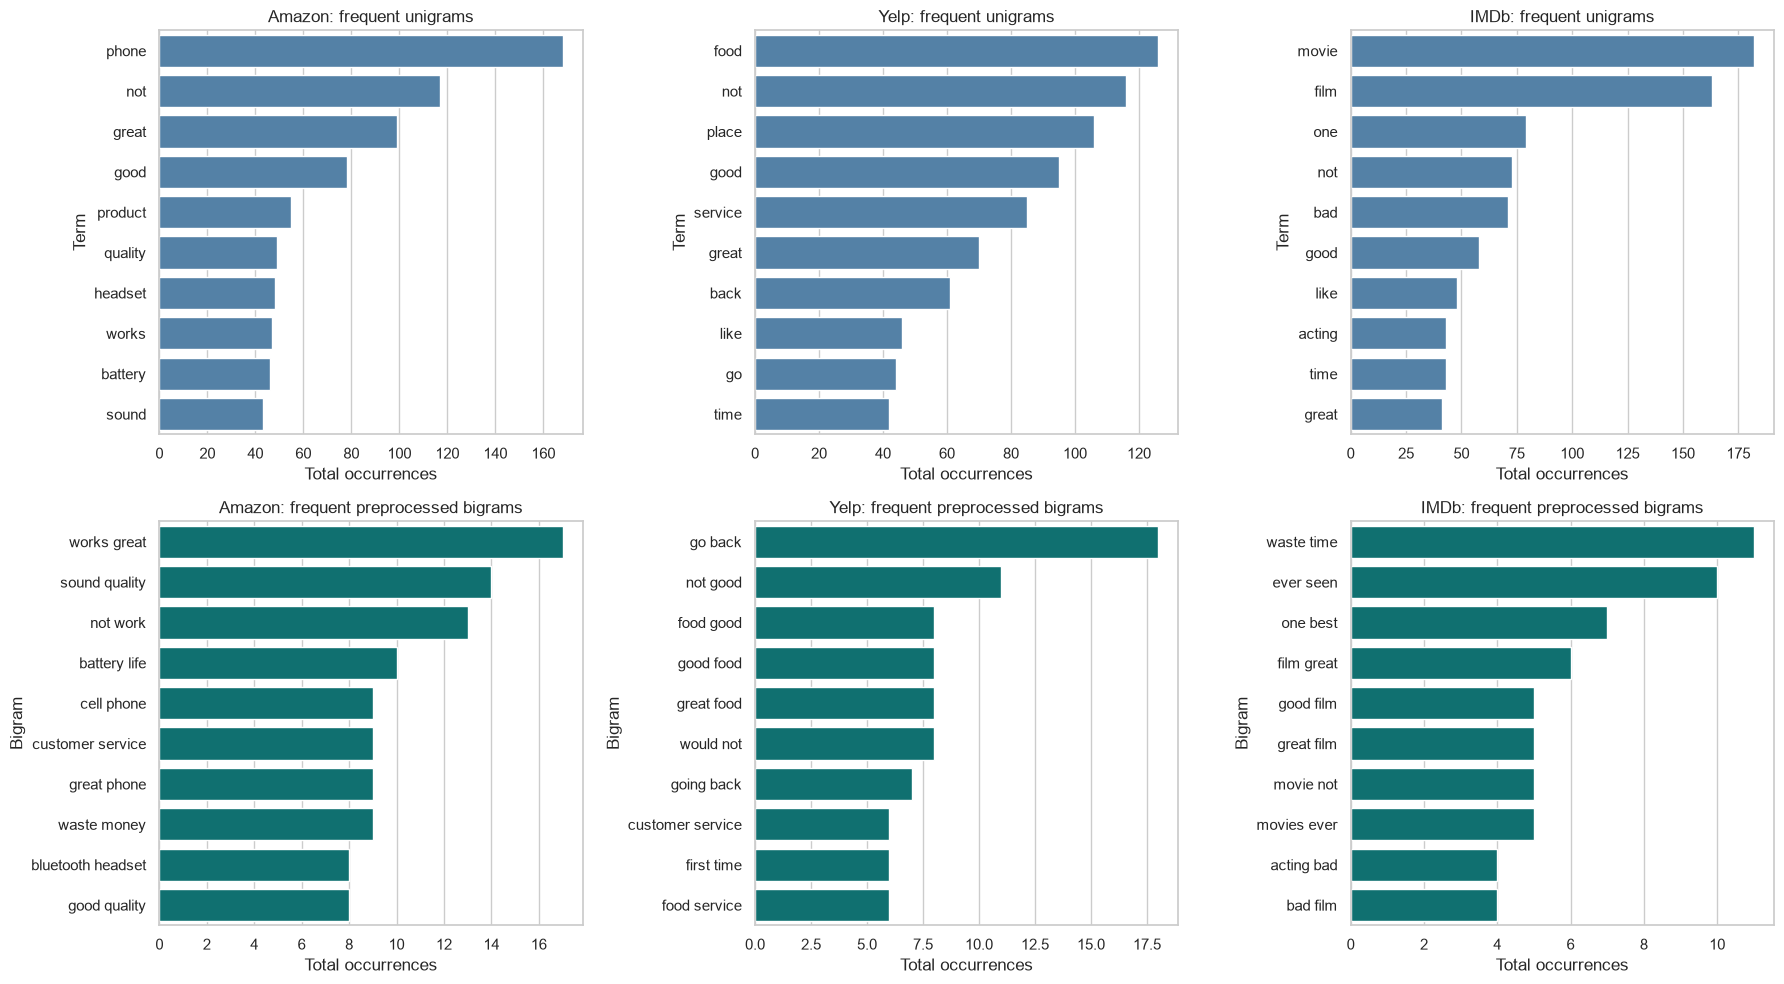

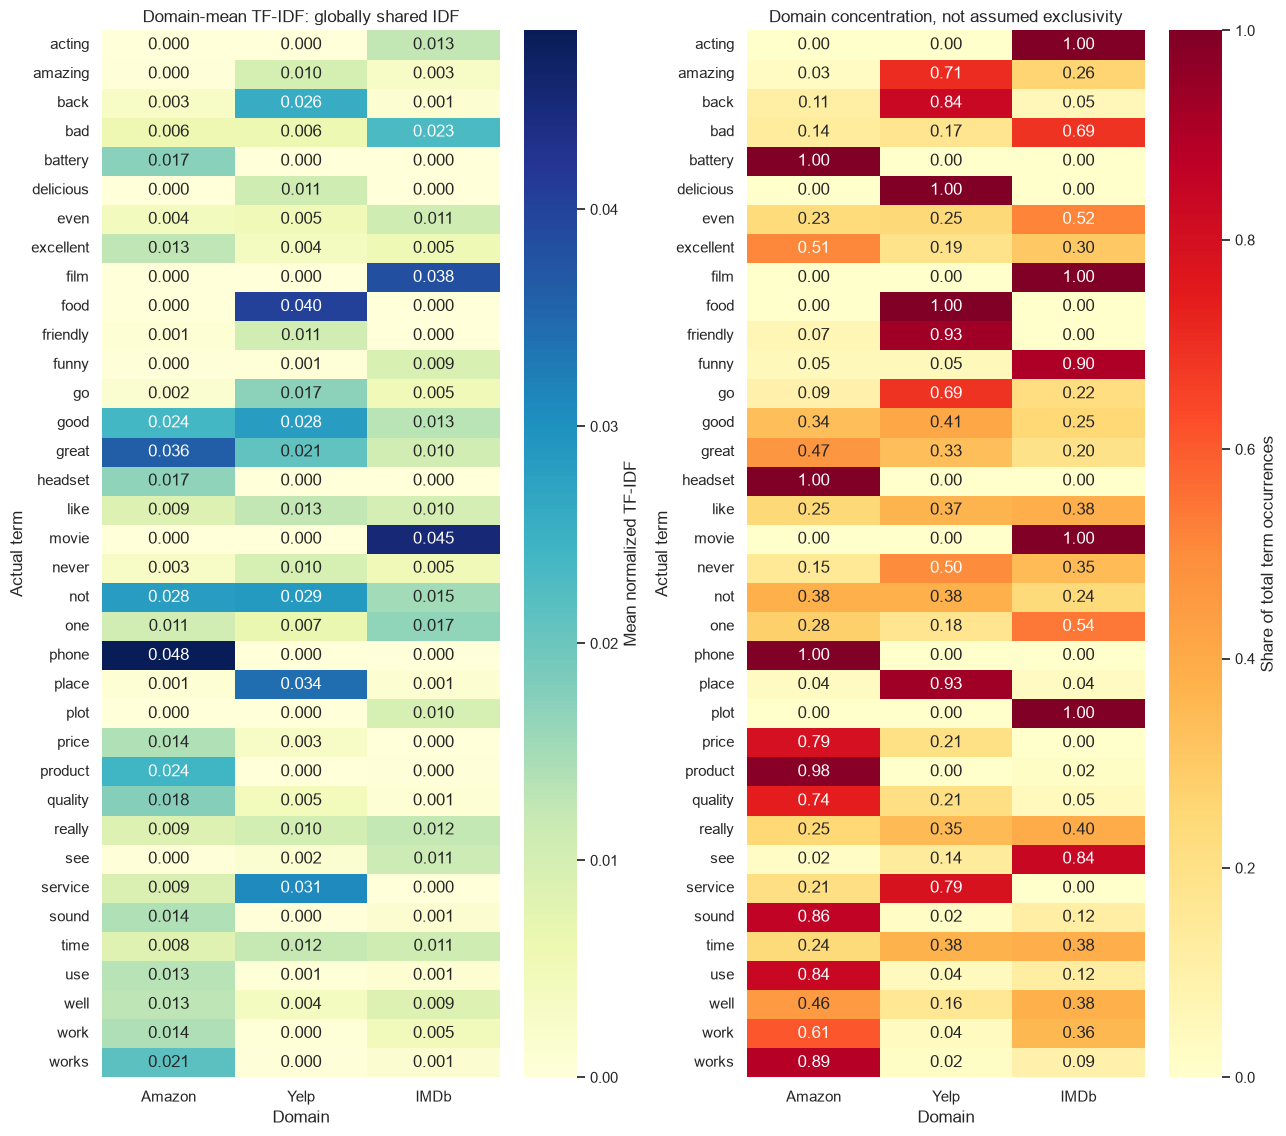

**Computed domain observations.**

- **Amazon:** frequent terms include `phone`, `not`, `great`, `good`, `product`; frequent bigrams include `works great`, `sound quality`, `not work`. The leading domain-mean TF-IDF term is `phone` (0.0482). Among the combined top domain-mean terms, `battery` has the largest occurrence share in this domain (100.0%); its document frequencies are Amazon: 45, Yelp: 0, IMDb: 0.
- **Yelp:** frequent terms include `food`, `not`, `place`, `good`, `service`; frequent bigrams include `go back`, `not good`, `food good`. The leading domain-mean TF-IDF term is `food` (0.0402). Among the combined top domain-mean terms, `delicious` has the largest occurrence share in this domain (100.0%); its document frequencies are Amazon: 0, Yelp: 23, IMDb: 0.
- **IMDb:** frequent terms include `movie`, `film`, `one`, `not`, `bad`; frequent bigrams include `waste time`, `ever seen`, `one best`. The leading domain-mean TF-IDF term is `movie` (0.0451). Among the combined top domain-mean terms, `acting` has the largest occurrence share in this domain (100.0%); its document frequencies are Amazon: 0, Yelp: 0, IMDb: 43.

Across the full vocabulary, **417 types occur in all three domains**. The observed domain vocabulary sizes are Amazon: 1,691, Yelp: 1,892, IMDb: 2,897. The exclusivity table is computed from zero counts in the other domains and applies only to this dataset, not to language generally. Domain vocabulary differences widen the combined feature space, whereas shared evaluative terms connect domains. The frequency and concentration tables distinguish topic-related concentration from widely shared review language; TF-IDF alone does not establish semantic domain membership.

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for column, domain in enumerate(DOMAINS):
    term_data = frequent_terms[frequent_terms['Domain'].eq(domain)].head(10)
    pair_data = frequent_bigrams[frequent_bigrams['Domain'].eq(domain)].head(10)
    sns.barplot(data=term_data, x='Total occurrences', y='Term', color='steelblue', ax=axes[0, column])
    sns.barplot(data=pair_data, x='Total occurrences', y='Bigram', color='teal', ax=axes[1, column])
    axes[0, column].set_title(f'{domain}: frequent unigrams')
    axes[1, column].set_title(f'{domain}: frequent preprocessed bigrams')
fig.tight_layout()
plt.show()

heatmap_means = pd.DataFrame({domain: domain_tfidf_means[domain][candidate_positions] for domain in DOMAINS}, index=candidate_terms)
fig, axes = plt.subplots(1, 2, figsize=(13, max(8, len(candidate_terms) * 0.32)))
sns.heatmap(heatmap_means, cmap='YlGnBu', annot=True, fmt='.3f', ax=axes[0], cbar_kws={'label': 'Mean normalized TF-IDF'})
sns.heatmap(term_domain_shares, cmap='YlOrRd', annot=True, fmt='.2f', vmin=0, vmax=1, ax=axes[1], cbar_kws={'label': 'Share of total term occurrences'})
axes[0].set_title('Domain-mean TF-IDF: globally shared IDF')
axes[1].set_title('Domain concentration, not assumed exclusivity')
for ax in axes:
    ax.set_xlabel('Domain')
    ax.set_ylabel('Actual term')
fig.tight_layout()
plt.show()

domain_observations = []
for domain in DOMAINS:
    top_terms = frequent_terms[frequent_terms['Domain'].eq(domain)].head(5)['Term'].tolist()
    top_pairs = frequent_bigrams[frequent_bigrams['Domain'].eq(domain)].head(3)['Bigram'].tolist()
    mean_winner = domain_mean_terms[domain_mean_terms['Domain'].eq(domain)].iloc[0]
    concentrated_term = term_domain_shares[domain].idxmax()
    share = term_domain_shares.at[concentrated_term, domain]
    frequencies = ', '.join(f'{other}: {int(term_domain_frequencies.at[concentrated_term, other])}' for other in DOMAINS)
    domain_observations.append(f'- **{domain}:** frequent terms include {", ".join(f"`{term}`" for term in top_terms)}; frequent bigrams include {", ".join(f"`{pair}`" for pair in top_pairs)}. The leading domain-mean TF-IDF term is `{mean_winner["Term"]}` ({mean_winner["Domain-mean TF-IDF (shared fit)"]:.4f}). Among the combined top domain-mean terms, `{concentrated_term}` has the largest occurrence share in this domain ({share:.1%}); its document frequencies are {frequencies}.')
display(Markdown('**Computed domain observations.**\n\n' + '\n'.join(domain_observations) + f'\n\nAcross the full vocabulary, **{shared_types:,} types occur in all three domains**. The observed domain vocabulary sizes are ' + ', '.join(f'{domain}: {domain_vocabulary_sizes[domain]:,}' for domain in DOMAINS) + '. The exclusivity table is computed from zero counts in the other domains and applies only to this dataset, not to language generally. Domain vocabulary differences widen the combined feature space, whereas shared evaluative terms connect domains. The frequency and concentration tables distinguish topic-related concentration from widely shared review language; TF-IDF alone does not establish semantic domain membership.'))

## 9. Comparison and Discussion

The following table distinguishes **word-level** and **document-level** representations. Dimensionality, nonzero counts, and density are measured from the actual matrices. The discussion cites computed examples and makes a descriptive choice; no predictive superiority is claimed because no models are trained or evaluated.

,Representation,Unit,Frequency,Word order,Importance weighting,Dimensions per vector,Main limitation
0,One-hot,Word,No,No,No,4953,No semantics; V coordinates for one token
1,BoW,Document,Raw token counts,No,No,4953,Frequent generic words; loses order
2,Bigrams,Document,Raw pair counts,Local final-token adjacency only,No,14026,Sparse; no long-range structure; altered adjacency
3,TF-IDF,Document,TF contributes before L2 normalization,No,Shared smoothed IDF,4953,Rare noise can score highly; no context


,Representation,Documents,Features,Nonzero entries,Density (%)
0,BoW,3000,4953,18096,0.122
1,Bigrams,3000,14026,15431,0.037
2,TF-IDF,3000,4953,18096,0.122


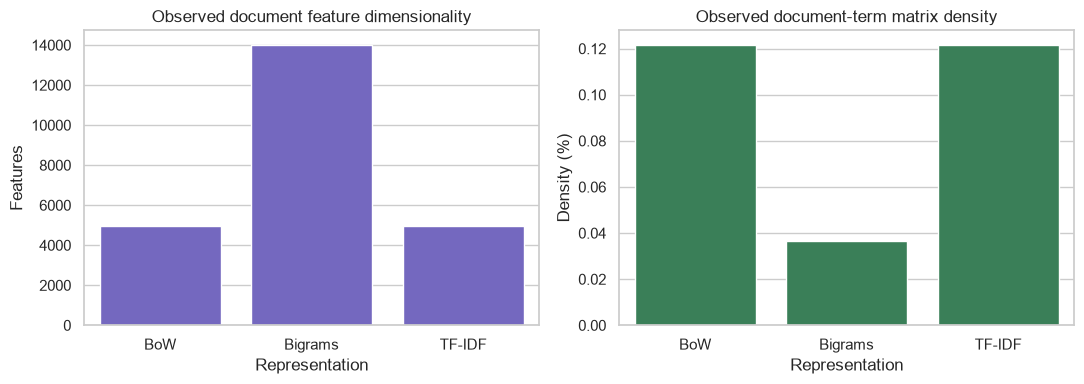

### Answers grounded in the results

1. **Main difference between BoW and TF-IDF.** Both have 4,953 columns here and use the same vocabulary, but BoW records raw occurrence counts whereas TF-IDF weights those counts by corpus document rarity and normalizes each document. For example, BoW assigns `said` a count of 3 in document 1236; TF-IDF changes that value using its IDF and the document norm. The individual TF-IDF leaders are Amazon: `currently` (0.3110); Yelp: `dishes` (0.3998); IMDb: `versus` (0.3114). Their displayed TF, document frequency, and IDF explain the scores, rather than assuming that high scores mean positive sentiment.

2. **Information captured by bigrams.** The actual pair `not good` links a retained negation to a neighboring final token, whereas unigram BoW separates the two words. The observed pair `not good` is the most frequent bigram, with 22 occurrences. Pair features encode local order but not full syntax; stopword deletion can create new adjacency.

3. **Most informative representation for this descriptive task.** **TF-IDF is the most useful primary representation for examining weighted review vocabulary**, because it distinguishes repetition from corpus rarity, provides document-specific rankings, and supports shared-scale domain summaries. The domain-mean leaders are Amazon: `phone`; Yelp: `food`; IMDb: `movie`, while the three individual-document leaders differ from these aggregate summaries where the computed tables indicate differences. This is an interpretability judgment, not an accuracy result. Bigrams provide complementary phrase and negation information that unigram TF-IDF lacks; no single representation is universally superior.

4. **Effect of domain diversity.** Domain vocabularies contain Amazon: 1,691, Yelp: 1,892, IMDb: 2,897 types, and 417 types occur in all domains. Their union contains 4,953 types. The domain term, bigram, and occurrence-share tables demonstrate which features are concentrated and which are shared; concentration must not be described as exclusivity without zero counts elsewhere. Combining domains broadens the feature space and changes the global document frequencies used for IDF.

5. **Limitations.** One-hot vectors encode identity only and have no word similarity. BoW ignores order and does not discount generic words. Bigrams add 14,026 dimensions and represent only local preprocessed adjacency; uncommon pairs fragment evidence. TF-IDF still ignores order, may emphasize rare artifacts, and depends on the fitted corpus. All four methods are sparse lexical representations without contextual semantics, sarcasm understanding, or reliable handling of contracted negation. The punctuation-first pipeline also loses numbers and emphasis. Retained duplicate records influence frequencies; 3 documents become empty after preprocessing. Selection of long reviews makes the individual examples illustrative rather than population-representative.

In [11]:
comparison = pd.DataFrame([
    {'Representation': 'One-hot', 'Unit': 'Word', 'Frequency': 'No', 'Word order': 'No', 'Importance weighting': 'No', 'Dimensions per vector': len(vocabulary), 'Main limitation': 'No semantics; V coordinates for one token'},
    {'Representation': 'BoW', 'Unit': 'Document', 'Frequency': 'Raw token counts', 'Word order': 'No', 'Importance weighting': 'No', 'Dimensions per vector': bow_matrix.shape[1], 'Main limitation': 'Frequent generic words; loses order'},
    {'Representation': 'Bigrams', 'Unit': 'Document', 'Frequency': 'Raw pair counts', 'Word order': 'Local final-token adjacency only', 'Importance weighting': 'No', 'Dimensions per vector': bigram_matrix.shape[1], 'Main limitation': 'Sparse; no long-range structure; altered adjacency'},
    {'Representation': 'TF-IDF', 'Unit': 'Document', 'Frequency': 'TF contributes before L2 normalization', 'Word order': 'No', 'Importance weighting': 'Shared smoothed IDF', 'Dimensions per vector': tfidf_matrix.shape[1], 'Main limitation': 'Rare noise can score highly; no context'}
])
display(comparison)
representation_metrics = pd.DataFrame([{'Representation': name, 'Documents': matrix.shape[0], 'Features': matrix.shape[1], 'Nonzero entries': matrix.nnz, 'Density (%)': 100 * matrix.nnz / (matrix.shape[0] * matrix.shape[1])} for name, matrix in [('BoW', bow_matrix), ('Bigrams', bigram_matrix), ('TF-IDF', tfidf_matrix)]])
display(representation_metrics.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=representation_metrics, x='Representation', y='Features', color='slateblue', ax=axes[0])
sns.barplot(data=representation_metrics, x='Representation', y='Density (%)', color='seagreen', ax=axes[1])
axes[0].set_title('Observed document feature dimensionality')
axes[1].set_title('Observed document-term matrix density')
fig.tight_layout()
plt.show()

individual_winners = '; '.join(f'{table.iloc[0]["Domain"]}: `{table.iloc[0]["Term"]}` ({table.iloc[0]["Individual-document TF-IDF"]:.4f})' for table in individual_tables)
mean_winners = '; '.join(f'{domain}: `{domain_mean_terms[domain_mean_terms["Domain"].eq(domain)].iloc[0]["Term"]}`' for domain in DOMAINS)
phrase = negation_examples[0]['Bigram']
display(Markdown(f'''### Answers grounded in the results

1. **Main difference between BoW and TF-IDF.** Both have {bow_matrix.shape[1]:,} columns here and use the same vocabulary, but BoW records raw occurrence counts whereas TF-IDF weights those counts by corpus document rarity and normalizes each document. For example, BoW assigns `{example_word}` a count of {example_count} in document {example_doc}; TF-IDF changes that value using its IDF and the document norm. The individual TF-IDF leaders are {individual_winners}. Their displayed TF, document frequency, and IDF explain the scores, rather than assuming that high scores mean positive sentiment.

2. **Information captured by bigrams.** The actual pair `{phrase}` links a retained negation to a neighboring final token, whereas unigram BoW separates the two words. The observed pair `{bigram_features[bigram_top[0]]}` is the most frequent bigram, with {int(bigram_totals[bigram_top[0]])} occurrences. Pair features encode local order but not full syntax; stopword deletion can create new adjacency.

3. **Most informative representation for this descriptive task.** **TF-IDF is the most useful primary representation for examining weighted review vocabulary**, because it distinguishes repetition from corpus rarity, provides document-specific rankings, and supports shared-scale domain summaries. The domain-mean leaders are {mean_winners}, while the three individual-document leaders differ from these aggregate summaries where the computed tables indicate differences. This is an interpretability judgment, not an accuracy result. Bigrams provide complementary phrase and negation information that unigram TF-IDF lacks; no single representation is universally superior.

4. **Effect of domain diversity.** Domain vocabularies contain {', '.join(f'{domain}: {domain_vocabulary_sizes[domain]:,}' for domain in DOMAINS)} types, and {shared_types:,} types occur in all domains. Their union contains {len(vocabulary):,} types. The domain term, bigram, and occurrence-share tables demonstrate which features are concentrated and which are shared; concentration must not be described as exclusivity without zero counts elsewhere. Combining domains broadens the feature space and changes the global document frequencies used for IDF.

5. **Limitations.** One-hot vectors encode identity only and have no word similarity. BoW ignores order and does not discount generic words. Bigrams add {bigram_matrix.shape[1]:,} dimensions and represent only local preprocessed adjacency; uncommon pairs fragment evidence. TF-IDF still ignores order, may emphasize rare artifacts, and depends on the fitted corpus. All four methods are sparse lexical representations without contextual semantics, sarcasm understanding, or reliable handling of contracted negation. The punctuation-first pipeline also loses numbers and emphasis. Retained duplicate records influence frequencies; {empty_documents} documents become empty after preprocessing. Selection of long reviews makes the individual examples illustrative rather than population-representative.'''))

## 10. Conclusion

The conclusion below is generated from the executed analyses so that its quantitative claims remain tied to the actual loaded dataset. A final validation cell checks sample preservation, vocabulary alignment, readable sample sizes, negation preservation, and feature-count identities. These checks validate the representations, not their effectiveness in a prediction task.

In [12]:
display(Markdown(f'''This project downloaded and verified **{len(df):,} labelled reviews** spanning Amazon, Yelp, and IMDb, preserved their source domains and original texts, and applied a reproducible four-step preprocessing pipeline. The final vocabulary contained **{len(vocabulary):,} word types**. Word-level one-hot encoding and document-level BoW, bigrams, and TF-IDF were implemented without training a model.

The observed unigram and bigram matrices contained {bow_matrix.shape[1]:,} and {bigram_matrix.shape[1]:,} features respectively. TF-IDF was the most informative primary representation for this descriptive vocabulary analysis because its displayed scores explain how repetition and corpus rarity combine. Actual negation bigrams, including `{phrase}`, contributed local phrase information unavailable in unigram features. Domain frequency and shared-IDF analyses demonstrated vocabulary overlap and concentration, with {shared_types:,} word types observed across all three domains.

The principal limitations are high-dimensional sparsity, lost contextual semantics and global order, preprocessing-induced information loss, and corpus-dependent weighting. Domain diversity expands the vocabulary and affects IDF, while duplicates contribute repeated evidence. These findings concern descriptive representation, not demonstrated predictive performance.'''))

assert len(df) == 3000
assert domain_counts.eq(1000).all() and domain_labels.eq(500).all().all()
assert df['Original_Text'].equals(original_snapshot)
assert onehot_sample.shape == (10, len(vocabulary)) and onehot_sample.nnz == 10
assert bow_matrix.shape == tfidf_matrix.shape == (3000, len(vocabulary))
assert bigram_matrix.shape[0] == 3000
assert bow_sample.shape == tfidf_sample.shape == (6, 15)
assert bigram_sample.shape[0] >= 5 and bigram_sample.shape[1] >= 15
assert len(bigram_top) >= 20
assert all(len(table) == 15 for table in individual_tables)
assert set(individual_top_terms['Domain']) == set(DOMAINS)
assert NEGATIONS.isdisjoint(stop_words)
for word in NEGATIONS:
    assert word in vocab_to_index and negation_counts[word] > 0
assert np.array_equal(np.asarray(bow_matrix.sum(axis=1)).ravel(), df['Final_Tokens'].map(len).to_numpy())
assert np.array_equal(np.asarray(bigram_matrix.sum(axis=1)).ravel(), np.maximum(df['Final_Tokens'].map(len).to_numpy() - 1, 0))
assert bow_matrix.nnz == tfidf_matrix.nnz
print('Validation passed: all 3,000 reviews retained; four representations verified; domain and individual analyses kept distinct.')

This project downloaded and verified **3,000 labelled reviews** spanning Amazon, Yelp, and IMDb, preserved their source domains and original texts, and applied a reproducible four-step preprocessing pipeline. The final vocabulary contained **4,953 word types**. Word-level one-hot encoding and document-level BoW, bigrams, and TF-IDF were implemented without training a model.

The observed unigram and bigram matrices contained 4,953 and 14,026 features respectively. TF-IDF was the most informative primary representation for this descriptive vocabulary analysis because its displayed scores explain how repetition and corpus rarity combine. Actual negation bigrams, including `not good`, contributed local phrase information unavailable in unigram features. Domain frequency and shared-IDF analyses demonstrated vocabulary overlap and concentration, with 417 word types observed across all three domains.

The principal limitations are high-dimensional sparsity, lost contextual semantics and global order, preprocessing-induced information loss, and corpus-dependent weighting. Domain diversity expands the vocabulary and affects IDF, while duplicates contribute repeated evidence. These findings concern descriptive representation, not demonstrated predictive performance.

Validation passed: all 3,000 reviews retained; four representations verified; domain and individual analyses kept distinct.
